<a href="https://colab.research.google.com/github/agboolafaith733-cpu/OIBSIP/blob/main/%20%20%20Task%203%20-%20Sales%20Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# TASK 3 - SALES PREDICTION
# Predict Sales based on Advertising Spend (TV, Radio, Newspaper)
# Using Linear Regression

# STEP 1 - Import Libraries and Load Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load Advertising Dataset
url = "https://raw.githubusercontent.com/justmarkham/DAT7/master/data/Advertising.csv"
sales = pd.read_csv(url)

print("Dataset Shape:", sales.shape)
print(sales.head())
print(sales.info())

HTTPError: HTTP Error 404: Not Found

In [ ]:
# TASK 3 - SALES PREDICTION
# Predict Sales based on Advertising Spend (TV, Radio, Newspaper)

# STEP 1 - Import Libraries and Load Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load Advertising Dataset - working link
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"
sales = pd.read_csv(url)

print("Dataset Shape:", sales.shape)
print(sales.head())
print(sales.info())

Dataset Shape: (200, 5)
   Unnamed: 0     TV  radio  newspaper  sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB
None


After cleaning:
      TV  radio  newspaper  sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9
               TV       radio   newspaper       sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000

Correlation with Sales:
TV           0.782224
radio        0.576223
newspaper    0.228299
sales        1.000000
Name: sales, dtype: float64


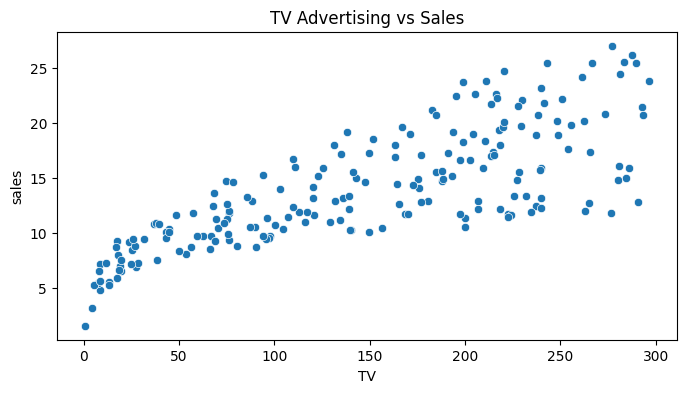

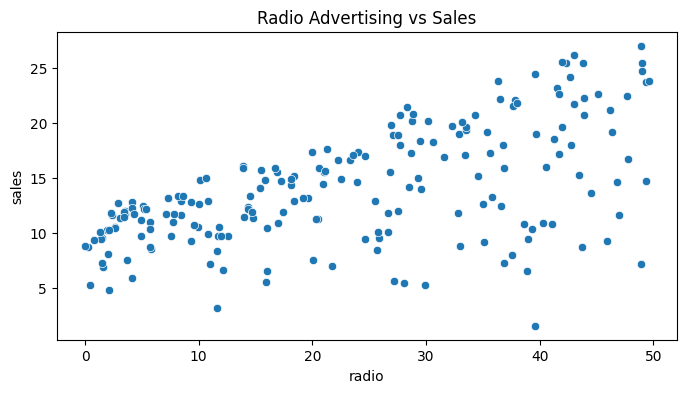

In [ ]:
# STEP 2 - Clean Data and Explore
# Remove the useless serial number column
sales = sales.drop(columns=['Unnamed: 0'])

print("After cleaning:")
print(sales.head())
print(sales.describe())

# Check which advert affects Sales most
print("\nCorrelation with Sales:")
print(sales.corr(numeric_only=True)['sales'])

# Draw graph - TV vs Sales
plt.figure(figsize=(8,4))
sns.scatterplot(x='TV', y='sales', data=sales)
plt.title('TV Advertising vs Sales')
plt.show()

# Draw graph - Radio vs Sales
plt.figure(figsize=(8,4))
sns.scatterplot(x='radio', y='sales', data=sales)
plt.title('Radio Advertising vs Sales')
plt.show()

In [4]:
# STEP 3 - Split Data and Train Model
# X = wetin we know (TV, Radio, Newspaper)
# y = wetin we want predict (Sales)

X = sales[['TV', 'radio', 'newspaper']]
y = sales['sales']

# Split: 80% to teach, 20% to test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

# Create and Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel don learn finish!")
print("Coefficients (how much each advert contributes):", model.coef_)
print("Intercept:", model.intercept_)

Train size: (160, 3)
Test size: (40, 3)

Model don learn finish!
Coefficients (how much each advert contributes): [0.04472952 0.18919505 0.00276111]
Intercept: 2.979067338122629


R2 Score: 0.899438024100912
Mean Squared Error: 3.1740973539761033
   Actual Sales  Predicted Sales
0          16.9        16.408024
1          22.4        20.889882
2          21.4        21.553843
3           7.3        10.608503
4          24.7        22.112373
5          12.6        13.105592
6          22.3        21.057192
7           8.4         7.461010
8          11.5        13.606346
9          14.9        15.155070

If you spend TV=150, Radio=25, Newspaper=30, Predicted Sales = 14.50


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


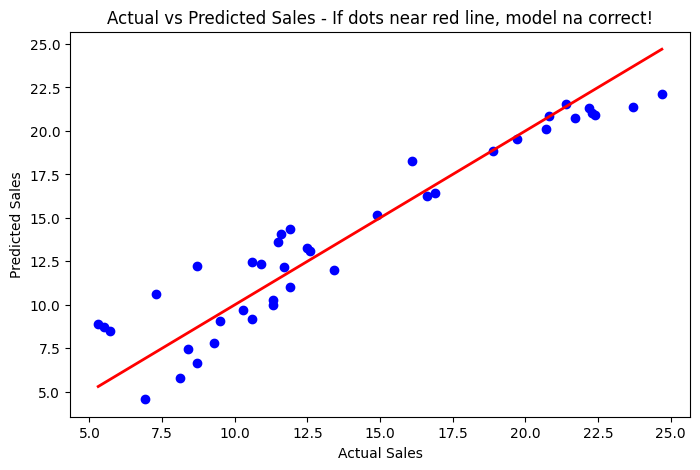

In [5]:
# STEP 4 - Test Model and Predict
# Make prediction for the 40 test rows
y_pred = model.predict(X_test)

# Check how correct we are
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

# Compare Actual vs Predicted for first 10
comparison = pd.DataFrame({'Actual Sales': y_test.values, 'Predicted Sales': y_pred})
print(comparison.head(10))

# Predict for NEW example: TV=150, Radio=25, Newspaper=30
new_advert = [[150, 25, 30]]
predicted_sales = model.predict(new_advert)
print(f"\nIf you spend TV=150, Radio=25, Newspaper=30, Predicted Sales = {predicted_sales[0]:.2f}")

# Graph - Actual vs Predicted
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales - If dots near red line, model na correct!')
plt.show()